# Business problem statement

A leading financial institution wants to develop an intelligent Anti-Money Laundering detection system using Artificial Neural Networks to identify suspicious financial transactions. The existing rule-based system generates a large number of false alerts and fails to detect sophisticated money laundering patterns. The bank wants to leverage historical transaction data and customer behavioral patterns to build a predictive model that can classify transactions as legitimate or suspicious, thereby improving detection rates, reducing false positives, and supporting regulatory compliance

# Project Objective

The primary objective is to build a binary classification model using ANN to identify potentially suspicious financial transactions.

Technical objectives:
1. Analyze historical banking transaction data.
2. Perform exploratory data analysis (EDA).
3. Identify important transaction-level and customer-level features.
4. Handle missing values and categorical variables.
5. Apply feature scaling and preprocessing.
6. Handle imbalanced transaction classes.
7. Build an ANN architecture using TensorFlow/Keras.
8. Train the model to distinguish legitimate and suspicious transactions.
9. Optimize the model using hyperparameter tuning.
10. Evaluate the model using appropriate classification metrics.
11. Develop a prediction interface for real-time transaction monitoring.

# Expected business outcomes

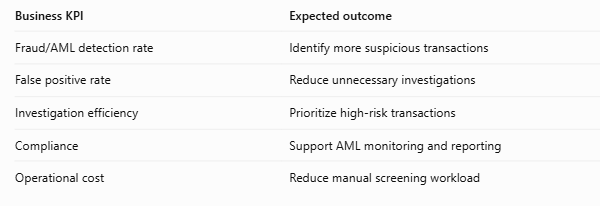

# Constraints

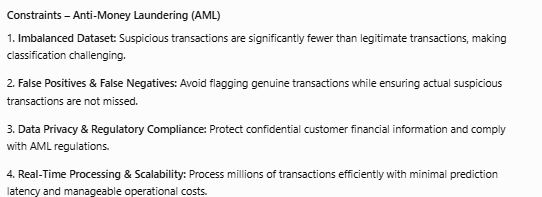

#### 1 b) Data understanding

##### Data Collection

In [2]:
!pip install kagglehub


  Attempting uninstall: certifi

    Found existing installation: certifi 2026.4.22

    Uninstalling certifi-2026.4.22:

      Successfully uninstalled certifi-2026.4.22

   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   -------------------------- ------------- 2/3 [kagglehub]
   -------------------------- ------------- 2/3 [kagglehub]
   -------------------------- ------------- 2/3

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [1]:
import kagglehub
import pandas as pd

In [2]:
link = r'berkanoztas/synthetic-transaction-monitoring-dataset-aml'
kagglehub.dataset_download(link,output_dir=r'C:\Users\LENOVO\OneDrive\New folder pro')

'C:\\Users\\LENOVO\\OneDrive\\New folder pro'

##### Data Description

In [2]:
df = pd.read_csv(r"C:\Users\LENOVO\OneDrive\New folder pro\SAML-D.csv")

In [3]:
df.shape

(9504852, 12)

In [4]:
df.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


In [4]:
df['Payment_currency'].unique()

array(['UK pounds', 'Indian rupee', 'Albanian lek', 'Swiss franc',
       'Pakistani rupee', 'Naira', 'Yen', 'Euro', 'Dirham',
       'Mexican Peso', 'Turkish lira', 'US dollar', 'Moroccan dirham'],
      dtype=object)

In [5]:
df['Received_currency'].unique()

array(['UK pounds', 'Dirham', 'Pakistani rupee', 'Euro', 'US dollar',
       'Mexican Peso', 'Indian rupee', 'Albanian lek', 'Turkish lira',
       'Naira', 'Swiss franc', 'Yen', 'Moroccan dirham'], dtype=object)

In [6]:
df['Sender_bank_location'].unique()

array(['UK', 'Albania', 'Nigeria', 'Japan', 'Spain', 'Switzerland', 'UAE',
       'Italy', 'France', 'Pakistan', 'Mexico', 'Austria', 'Germany',
       'Turkey', 'India', 'Morocco', 'USA', 'Netherlands'], dtype=object)

In [7]:
df['Receiver_bank_location'].unique()

array(['UK', 'UAE', 'Spain', 'France', 'USA', 'Mexico', 'Albania',
       'Turkey', 'Nigeria', 'Switzerland', 'Italy', 'Germany', 'Austria',
       'Netherlands', 'India', 'Pakistan', 'Morocco', 'Japan'],
      dtype=object)

In [8]:
df['Payment_type'].unique()

array(['Cash Deposit', 'Cross-border', 'Cheque', 'ACH', 'Credit card',
       'Debit card', 'Cash Withdrawal'], dtype=object)

In [5]:
df.dtypes

Time                       object
Date                       object
Sender_account              int64
Receiver_account            int64
Amount                    float64
Payment_currency           object
Received_currency          object
Sender_bank_location       object
Receiver_bank_location     object
Payment_type               object
Is_laundering               int64
Laundering_type            object
dtype: object

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9504852 entries, 0 to 9504851
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   Time                    object 
 1   Date                    object 
 2   Sender_account          int64  
 3   Receiver_account        int64  
 4   Amount                  float64
 5   Payment_currency        object 
 6   Received_currency       object 
 7   Sender_bank_location    object 
 8   Receiver_bank_location  object 
 9   Payment_type            object 
 10  Is_laundering           int64  
 11  Laundering_type         object 
dtypes: float64(1), int64(3), object(8)
memory usage: 870.2+ MB


#### 2.Data Preparation

##### a.Exploratory Data Analysis

##### Univariate Analysis

In [8]:
df.isna().sum()

Time                      0
Date                      0
Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Laundering_type           0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,Sender_account,Receiver_account,Amount,Is_laundering
count,9.504852e+06,9.504852e+06,9.504852e+06,9.504852e+06
mean,5.006619e+09,5.006006e+09,8.762968e+03,1.038733e-03
std,2.885814e+09,2.884763e+09,2.561495e+04,3.221263e-02
min,9.018000e+03,9.018000e+03,3.730000e+00,0.000000e+00
25%,2.513133e+09,2.513219e+09,2.143688e+03,0.000000e+00
50%,5.001017e+09,5.002572e+09,6.113720e+03,0.000000e+00
75%,7.505051e+09,7.502397e+09,1.045846e+04,0.000000e+00
max,9.999987e+09,9.999971e+09,1.261850e+07,1.000000e+00


In [11]:
df['Time']

0          10:35:19
1          10:35:20
2          10:35:20
3          10:35:21
4          10:35:21
             ...   
9504847    10:57:01
9504848    10:57:06
9504849    10:57:06
9504850    10:57:11
9504851    10:57:12
Name: Time, Length: 9504852, dtype: object

In [12]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

In [13]:
df['Amount'].mean()

np.float64(8762.967600927232)

In [14]:
df['Amount'].std()

25614.95299959768

In [15]:
df['Amount'].min()

3.73

In [16]:
df['Amount'].max()

12618498.4

In [17]:
df['Payment_currency'].unique()

array(['UK pounds', 'Indian rupee', 'Albanian lek', 'Swiss franc',
       'Pakistani rupee', 'Naira', 'Yen', 'Euro', 'Dirham',
       'Mexican Peso', 'Turkish lira', 'US dollar', 'Moroccan dirham'],
      dtype=object)

In [18]:
df['Payment_currency'].mode()

0    UK pounds
Name: Payment_currency, dtype: object

In [19]:
df['Payment_currency'].value_counts(normalize=True)  

Payment_currency
UK pounds          0.957331
Euro               0.012327
Turkish lira       0.002945
Swiss franc        0.002892
Dirham             0.002868
Pakistani rupee    0.002861
Naira              0.002856
US dollar          0.002742
Yen                0.002689
Moroccan dirham    0.002672
Mexican Peso       0.002615
Albanian lek       0.002607
Indian rupee       0.002594
Name: proportion, dtype: float64

In [20]:
df['Received_currency'].value_counts(normalize=True)

Received_currency
UK pounds          0.924123
Euro               0.024399
Pakistani rupee    0.004839
Yen                0.004820
Moroccan dirham    0.004813
Albanian lek       0.004812
Mexican Peso       0.004761
Naira              0.004739
Indian rupee       0.004604
US dollar          0.004594
Swiss franc        0.004517
Dirham             0.004503
Turkish lira       0.004476
Name: proportion, dtype: float64

In [21]:
df['Sender_bank_location'].value_counts(normalize=True)

Sender_bank_location
UK             0.966147
Turkey         0.002199
Switzerland    0.002157
Pakistan       0.002141
UAE            0.002113
Nigeria        0.002107
Spain          0.002040
Germany        0.002026
USA            0.002002
Italy          0.001988
France         0.001968
Japan          0.001943
Morocco        0.001940
Austria        0.001899
Mexico         0.001858
Albania        0.001857
India          0.001851
Netherlands    0.001764
Name: proportion, dtype: float64

In [22]:
df['Receiver_bank_location'].value_counts(normalize=True)

Receiver_bank_location
UK             0.932643
Pakistan       0.004101
Austria        0.004087
Albania        0.004080
Japan          0.004075
Morocco        0.004072
Germany        0.004055
France         0.004052
Mexico         0.004038
Nigeria        0.004027
Netherlands    0.003926
Spain          0.003923
India          0.003886
USA            0.003877
Italy          0.003842
Switzerland    0.003796
UAE            0.003777
Turkey         0.003744
Name: proportion, dtype: float64

In [30]:
df['Payment_type'].value_counts()

Payment_type
Credit card        2012909
Debit card         2012103
Cheque             2011419
ACH                2008807
Cross-border        933931
Cash Withdrawal     300477
Cash Deposit        225206
Name: count, dtype: int64

<Axes: ylabel='count'>

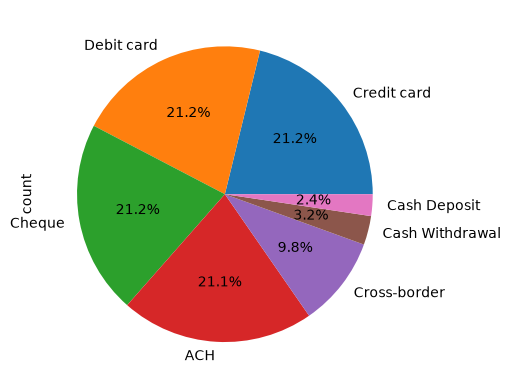

In [31]:
df['Payment_type'].value_counts().plot(kind='pie',autopct='%.1f%%')

In [32]:
df['Is_laundering'].value_counts()

Is_laundering
0    9494979
1       9873
Name: count, dtype: int64

<Axes: xlabel='Is_laundering'>

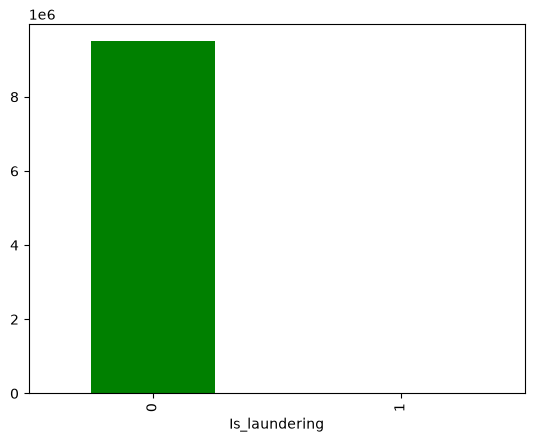

In [34]:
df['Is_laundering'].value_counts().plot(kind='bar',color=['green','red'])  # it is imbalanced Dataset

In [35]:
df['Laundering_type'].value_counts()

Laundering_type
Normal_Small_Fan_Out      3477717
Normal_Fan_Out            2302220
Normal_Fan_In             2104285
Normal_Group               528351
Normal_Cash_Withdrawal     305031
Normal_Cash_Deposits       223801
Normal_Periodical          210526
Normal_Plus_Mutual         155041
Normal_Mutual              125335
Normal_Foward               42031
Normal_single_large         20641
Structuring                  1870
Cash_Withdrawal              1334
Deposit-Send                  945
Smurfing                      932
Layered_Fan_In                656
Layered_Fan_Out               529
Stacked Bipartite             506
Behavioural_Change_1          394
Bipartite                     383
Cycle                         382
Fan_In                        364
Gather-Scatter                354
Behavioural_Change_2          345
Scatter-Gather                338
Single_large                  250
Fan_Out                       237
Over-Invoicing                 54
Name: count, dtype: int64

<Axes: xlabel='Laundering_type'>

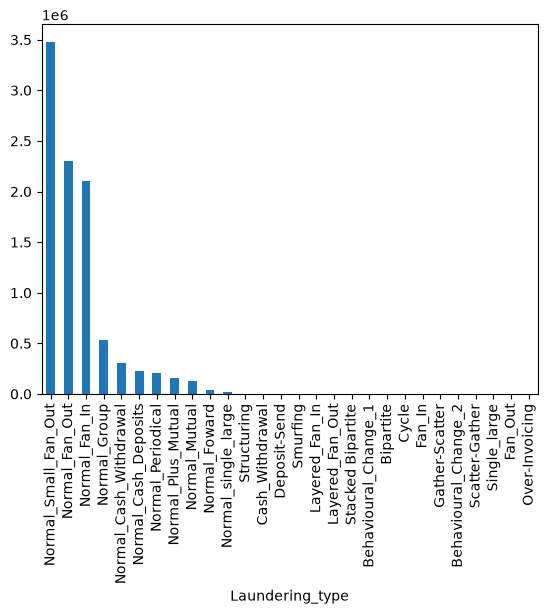

In [36]:
df['Laundering_type'].value_counts().plot(kind='bar')

<Axes: xlabel='Laundering_type'>

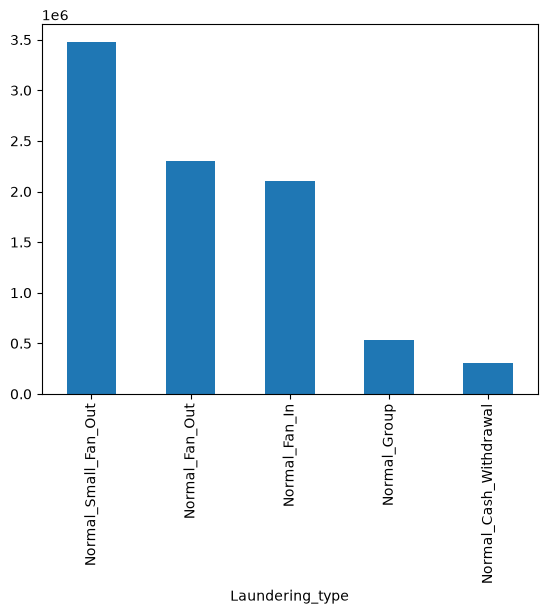

In [37]:
df['Laundering_type'].value_counts().nlargest(5).plot(kind='bar')

##### Bivariate Analysis

In [38]:
# categorical vs categorical

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

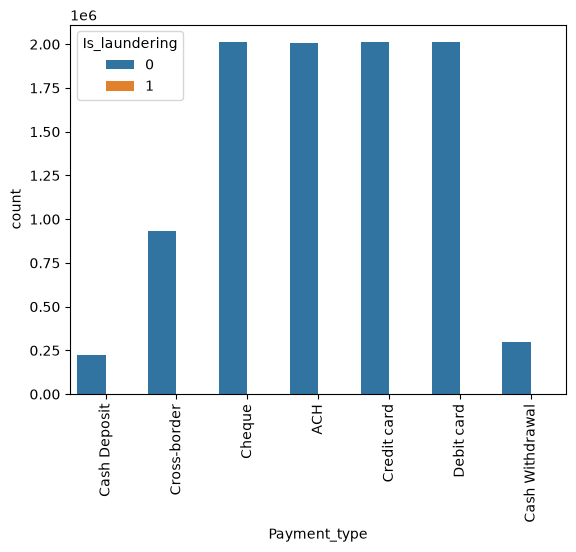

In [44]:
sns.countplot(x=df['Payment_type'],hue=df['Is_laundering'])
plt.xticks(rotation=90)
plt.show()

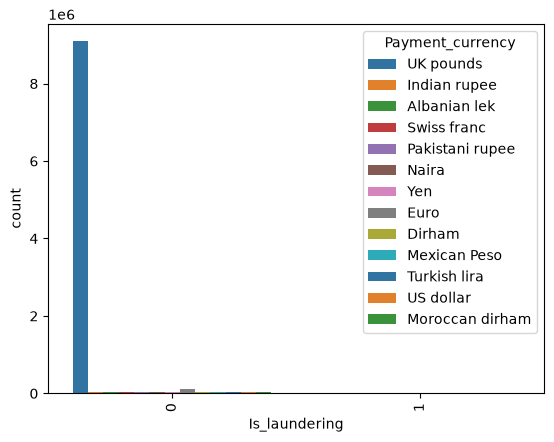

In [48]:
sns.countplot(hue=df['Payment_currency'],x=df['Is_laundering'],palette='tab10')
plt.xticks(rotation=90)
plt.show()

<Axes: xlabel='Is_laundering', ylabel='Amount'>

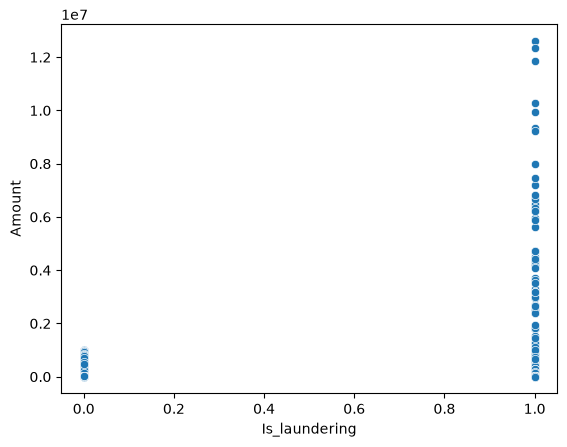

In [49]:
sns.scatterplot(x=df['Is_laundering'],y=df['Amount'])

In [50]:
# perform bivariate for more insights

#### Data Cleaning

In [7]:
df.dtypes

Time                       object
Date                       object
Sender_account              int64
Receiver_account            int64
Amount                    float64
Payment_currency           object
Received_currency          object
Sender_bank_location       object
Receiver_bank_location     object
Payment_type               object
Is_laundering               int64
Laundering_type            object
dtype: object

In [8]:
df['Sender_account'] = df['Sender_account'].astype('str')
df['Receiver_account'] = df['Receiver_account'].astype('str')

In [9]:
df['Date']=df['Date'].astype('datetime64[ns]')

In [10]:
df['Date'].dt.year

0          2022
1          2022
2          2022
3          2022
4          2022
           ... 
9504847    2023
9504848    2023
9504849    2023
9504850    2023
9504851    2023
Name: Date, Length: 9504852, dtype: int32

In [22]:
df['Date'].dt.month

0          10
1          10
2          10
3          10
4          10
           ..
9504847     8
9504848     8
9504849     8
9504850     8
9504851     8
Name: Date, Length: 9504852, dtype: int32

In [11]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

In [12]:
df.drop(columns=['Time','Date','Laundering_type','Sender_account', 'Receiver_account'],inplace=True)

In [13]:
df = df.sample(n=100000,random_state=23)

In [14]:
df.shape

(100000, 7)

In [15]:
X=df.drop(columns=['Is_laundering'])
y = df['Is_laundering']

In [16]:
X.columns

Index(['Amount', 'Payment_currency', 'Received_currency',
       'Sender_bank_location', 'Receiver_bank_location', 'Payment_type'],
      dtype='object')

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [18]:
cat_columns = X.select_dtypes(include=['object']).columns
numerical_columns = X.select_dtypes(exclude=['object']).columns

In [19]:
cat_columns

Index(['Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type'],
      dtype='object')

In [20]:
numerical_columns

Index(['Amount'], dtype='object')

In [21]:
cat_transformer = Pipeline([('OHE',OneHotEncoder(dtype='int'))])

In [22]:
numerical_transformer = Pipeline([('Scaling',StandardScaler())])

In [23]:
preprocess = ColumnTransformer([('cat_transformer',cat_transformer,cat_columns),
                  ('numerical_transformer',numerical_transformer,numerical_columns)])

In [24]:
preprocess

ColumnTransformer(transformers=[('cat_transformer',
                                 Pipeline(steps=[('OHE',
                                                  OneHotEncoder(dtype='int'))]),
                                 Index(['Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type'],
      dtype='object')),
                                ('numerical_transformer',
                                 Pipeline(steps=[('Scaling',
                                                  StandardScaler())]),
                                 Index(['Amount'], dtype='object'))])

In [25]:
from collections import Counter

In [26]:
Counter(y)

Counter({0: 99887, 1: 113})

In [48]:
!pip install imblearn

In [27]:
from imblearn.over_sampling import SMOTE

In [51]:
import sklearn
print(sklearn.__version__)

1.9.0


In [30]:
#pip uninstall scikit-learn imbalanced-learn -y

Found existing installation: scikit-learn 1.9.0
Uninstalling scikit-learn-1.9.0:
  Successfully uninstalled scikit-learn-1.9.0
Found existing installation: imbalanced-learn 0.14.0
Uninstalling imbalanced-learn-0.14.0:
  Successfully uninstalled imbalanced-learn-0.14.0
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


In [31]:
#pip install scikit-learn==1.5.2 imbalanced-learn==0.12.4

   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/11.0 MB 10.7 MB/s eta 0:00:01
   -------------- ------------------------- 3.9/11.0 MB 11.3 MB/s eta 0:00:01
   ---------------------- ----------------- 6.3/11.0 MB 11.3 MB/s eta 0:00:01
   ------------------------------- -------- 8.7/11.0 MB 11.4 MB/s eta 0:00:01
   ---------------------------------------  10.7/11.0 MB 11.4 MB/s eta 0:00:01
   ---------------------------------------- 11.0/11.0 MB 10.9 MB/s  0:00:01

   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ---------------------------------------- 0/2 [scikit-learn]
   ------------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlxtend 0.25.0 requires scikit-learn>=1.8.0, but you have scikit-learn 1.5.2 which is incompatible.


In [29]:
resampling = Pipeline([('Preprocessing',preprocess),
         ('SMOTE',SMOTE(random_state=23))])

In [30]:
resampling

Pipeline(steps=[('Preprocessing',
                 ColumnTransformer(transformers=[('cat_transformer',
                                                  Pipeline(steps=[('OHE',
                                                                   OneHotEncoder(dtype='int'))]),
                                                  Index(['Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type'],
      dtype='object')),
                                                 ('numerical_transformer',
                                                  Pipeline(steps=[('Scaling',
                                                                   StandardScaler())]),
                                                  Index(['Amount'], dtype='object'))])),
                ('SMOTE', SMOTE(random_state=23))])

In [32]:
X_s,y_s = resampling.fit_resample(X,y)

In [33]:
Counter(y_s)

Counter({0: 99887, 1: 99887})

#### Model Building

In [34]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense,BatchNormalization,Dropout

In [35]:
X_s.shape[1]

70

In [36]:
model = Sequential()

model.add(Input(shape=(X_s.shape[1],)))

model.add(Dense(units=16,activation='relu'))
model.add(Dense(units=8,activation='relu'))
model.add(Dense(units=4,activation='relu'))
model.add(Dense(units=2,activation='relu'))

model.add(Dense(units=1,activation='sigmoid'))

In [37]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [38]:
history = model.fit(X_s,y_s,epochs=30,validation_split=0.2)

Epoch 1/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step - accuracy: 0.7804 - loss: 0.4867 - val_accuracy: 0.6069 - val_loss: 0.6426
Epoch 2/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.8013 - loss: 0.4226 - val_accuracy: 0.6032 - val_loss: 0.6245
Epoch 3/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - accuracy: 0.8075 - loss: 0.3985 - val_accuracy: 0.6736 - val_loss: 0.5804
Epoch 4/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - accuracy: 0.8108 - loss: 0.3894 - val_accuracy: 0.6952 - val_loss: 0.5467
Epoch 5/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - accuracy: 0.8111 - loss: 0.3791 - val_accuracy: 0.7604 - val_loss: 0.4843
Epoch 6/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - accuracy: 0.8141 - loss: 0.3730 - val_accuracy: 0.7502 - val_loss: 0.4822
Epoch 7/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 24s 5ms/step - accuracy: 0.8157 - loss: 0.3697 - val_accuracy: 0.6936 - val_loss: 0.5573
Epoch 8/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 24s 5ms/step - accuracy: 0.8167 - loss: 0

In [39]:
epochs = range(1,31)
train_loss = history.history['loss']
val_loss = history.history['val_loss']

<Axes: >

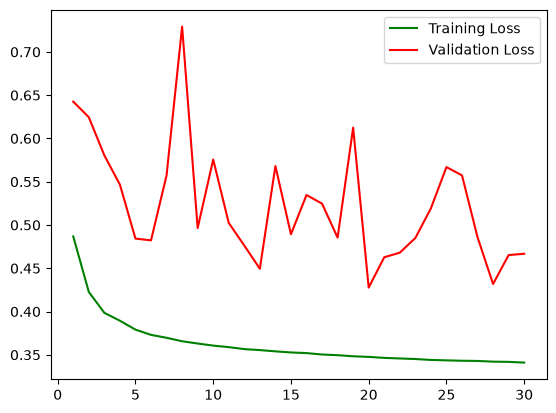

In [40]:
sns.lineplot(x=epochs,y=train_loss,label='Training Loss',color='green')
sns.lineplot(x=epochs,y=val_loss,label='Validation Loss',color='red')

#### Hyperparameter Tuning

In [42]:
import optuna
from tensorflow.keras.optimizers import RMSprop,SGD,Adam
from tensorflow.keras.callbacks import EarlyStopping

In [43]:
def objective(trial):

    #Search Space
    n_layers = trial.suggest_int('n_layers',1,4)
    learning_rate = trial.suggest_float('learning_rate',0.0001,0.1)
    batch_size = trial.suggest_categorical('batch_size',[16,32,64,128,256])
    optimizer_name = trial.suggest_categorical('optimizer',['adam','rmsprop','sgd'])

    #Buiding the model
    model = Sequential()
    model.add(Input(shape=(X_s.shape[1],)))
    for i in range(n_layers):
        units = trial.suggest_int("units_layer",2,32)
        dropout_rate = trial.suggest_float('dropout_layer',0.0,0.6)
        activation = trial.suggest_categorical('activatation',['relu','tanh','sigmoid'])

       
        model.add(Dense(units=units,activation=activation))
        model.add(Dropout(rate= dropout_rate))
        
    model.add(Dense(1,activation='sigmoid'))

    if optimizer_name == 'adam':
        optimizer = Adam(learning_rate=learning_rate)
    elif optimizer_name == 'rmsprop':
        optimizer = RMSprop(learning_rate=learning_rate)
    else:
        optimizer = SGD(learning_rate=learning_rate)

    model.compile(optimizer=optimizer,loss = 'binary_crossentropy',metrics=['accuracy'])

    early_stop  =EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)

    history = model.fit(X_s,y_s,validation_split=0.2,
              epochs=100,
              batch_size=batch_size,
              callbacks=[early_stop])

    best_loss = min(history.history['val_loss'])
    trial.set_user_attr('best_val_loss',float(best_loss))
    return best_loss
    
 

In [45]:
study = optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler())

[I 2026-11-11 12:18:14,439] A new study created in memory with name: no-name-00a235c6-8613-41a1-9747-7d4a661dac5a


In [46]:
study.optimize(objective,n_trials=30)

Epoch 1/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.6245 - loss: 0.6633 - val_accuracy: 0.0000e+00 - val_loss: 0.9640
Epoch 2/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.6250 - loss: 0.6626 - val_accuracy: 0.0000e+00 - val_loss: 1.0017
Epoch 3/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7223 - loss: 0.5863 - val_accuracy: 0.5933 - val_loss: 0.7970
Epoch 4/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.7755 - loss: 0.5317 - val_accuracy: 0.6002 - val_loss: 0.5679
Epoch 5/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.7762 - loss: 0.5278 - val_accuracy: 0.5958 - val_loss: 0.9668
Epoch 6/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.7757 - loss: 0.5219 - val_accuracy: 0.5957 - val_loss: 0.8490
Epoch 7/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7742 - loss: 0.5188 - val_accuracy: 0.6024 - val_loss: 0.6425
Epoch 8/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 

[I 2026-11-11 12:24:36,712] Trial 0 finished with value: 0.5679140686988831 and parameters: {'n_layers': 4, 'learning_rate': 0.05771930955578001, 'batch_size': 64, 'optimizer': 'rmsprop', 'units_layer': 27, 'dropout_layer': 0.4484053682776508, 'activatation': 'sigmoid'}. Best is trial 0 with value: 0.5679140686988831.


Epoch 1/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.6249 - loss: 0.6626 - val_accuracy: 0.0000e+00 - val_loss: 0.8725
Epoch 2/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.6851 - loss: 0.6157 - val_accuracy: 0.5278 - val_loss: 0.6229
Epoch 3/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7451 - loss: 0.5687 - val_accuracy: 0.5788 - val_loss: 0.8359
Epoch 4/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7486 - loss: 0.5656 - val_accuracy: 0.5890 - val_loss: 0.7644
Epoch 5/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.7490 - loss: 0.5653 - val_accuracy: 0.5938 - val_loss: 0.7712
Epoch 6/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7499 - loss: 0.5617 - val_accuracy: 0.5866 - val_loss: 0.8298
Epoch 7/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.7502 - loss: 0.5607 - val_accuracy: 0.6083 - val_loss: 0.6558


[I 2026-11-11 12:25:52,226] Trial 1 finished with value: 0.6228743195533752 and parameters: {'n_layers': 4, 'learning_rate': 0.04600642038417482, 'batch_size': 64, 'optimizer': 'rmsprop', 'units_layer': 7, 'dropout_layer': 0.4647090535542774, 'activatation': 'sigmoid'}. Best is trial 0 with value: 0.5679140686988831.


Epoch 1/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.7309 - loss: 0.5612 - val_accuracy: 0.5536 - val_loss: 0.8259
Epoch 2/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.7669 - loss: 0.5196 - val_accuracy: 0.5744 - val_loss: 0.7433
Epoch 3/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.7711 - loss: 0.5114 - val_accuracy: 0.5780 - val_loss: 0.7986
Epoch 4/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.7736 - loss: 0.5082 - val_accuracy: 0.5056 - val_loss: 0.9340
Epoch 5/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.7742 - loss: 0.5058 - val_accuracy: 0.5821 - val_loss: 0.7337
Epoch 6/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7757 - loss: 0.5034 - val_accuracy: 0.4986 - val_loss: 0.9374
Epoch 7/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7761 - loss: 0.5026 - val_accuracy: 0.6147 - val_loss: 0.5562
Epoch 8/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.7774 - loss: 

[I 2026-11-11 12:27:40,733] Trial 2 finished with value: 0.5561643242835999 and parameters: {'n_layers': 2, 'learning_rate': 0.035356849763481274, 'batch_size': 64, 'optimizer': 'sgd', 'units_layer': 32, 'dropout_layer': 0.2654913668999657, 'activatation': 'tanh'}. Best is trial 2 with value: 0.5561643242835999.


... (50 outputs left out)

Epoch 1/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.7393 - loss: 0.5473 - val_accuracy: 0.4515 - val_loss: 1.1538
Epoch 2/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.7797 - loss: 0.4762 - val_accuracy: 0.5523 - val_loss: 0.7182
Epoch 3/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.7897 - loss: 0.4445 - val_accuracy: 0.8900 - val_loss: 0.3256
Epoch 4/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.7957 - loss: 0.4231 - val_accuracy: 0.6837 - val_loss: 0.6283
Epoch 5/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.7982 - loss: 0.4117 - val_accuracy: 0.5907 - val_loss: 0.7590
Epoch 6/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.8007 - loss: 0.4043 - val_accuracy: 0.5987 - val_loss: 0.5758
Epoch 7/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.8034 - loss: 0.3987 - val_accuracy: 0.5293 - val_loss: 0.7146
Epoch 8/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - accuracy: 0.8041 -

[I 2026-11-11 14:04:28,221] Trial 28 finished with value: 0.3256050646305084 and parameters: {'n_layers': 4, 'learning_rate': 0.04070829468551368, 'batch_size': 64, 'optimizer': 'sgd', 'units_layer': 22, 'dropout_layer': 0.0401513606124614, 'activatation': 'relu'}. Best is trial 15 with value: 0.20451630651950836.


Epoch 1/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - accuracy: 0.7521 - loss: 0.5290 - val_accuracy: 0.5466 - val_loss: 0.7743
Epoch 2/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.7819 - loss: 0.4626 - val_accuracy: 0.5526 - val_loss: 0.6845
Epoch 3/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.7907 - loss: 0.4329 - val_accuracy: 0.8590 - val_loss: 0.3758
Epoch 4/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.7952 - loss: 0.4177 - val_accuracy: 0.6819 - val_loss: 0.5910
Epoch 5/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.7985 - loss: 0.4070 - val_accuracy: 0.8879 - val_loss: 0.3746
Epoch 6/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.8004 - loss: 0.3987 - val_accuracy: 0.5980 - val_loss: 0.5633
Epoch 7/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 23s 7ms/step - accuracy: 0.8030 - loss: 0.3936 - val_accuracy: 0.5229 - val_loss: 0.7293
Epoch 8/100
2498/2498 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.8036 -

[I 2026-11-11 14:07:27,997] Trial 29 finished with value: 0.3745900094509125 and parameters: {'n_layers': 3, 'learning_rate': 0.0633903830915331, 'batch_size': 64, 'optimizer': 'sgd', 'units_layer': 29, 'dropout_layer': 0.05548677492179711, 'activatation': 'relu'}. Best is trial 15 with value: 0.20451630651950836.


In [47]:
study.best_params

{'n_layers': 3,
 'learning_rate': 0.036359628819056106,
 'batch_size': 64,
 'optimizer': 'sgd',
 'units_layer': 19,
 'dropout_layer': 0.03252372180677059,
 'activatation': 'relu'}

In [48]:
model = Sequential()

model.add(Input(shape=(X_s.shape[1],)))

model.add(Dense(units=19,activation='relu'))
model.add(Dense(units=19,activation='relu'))
model.add(Dense(units=19,activation='relu'))

model.add(Dense(units=1,activation='sigmoid'))

In [49]:
model.compile(optimizer='sgd',loss='binary_crossentropy',metrics=['accuracy'])

In [50]:
history = model.fit(X_s,y_s,epochs=30,validation_split=0.2)

Epoch 1/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 31s 6ms/step - accuracy: 0.7048 - loss: 0.5780 - val_accuracy: 0.5475 - val_loss: 0.8288
Epoch 2/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 28s 6ms/step - accuracy: 0.7701 - loss: 0.5079 - val_accuracy: 0.5132 - val_loss: 0.9104
Epoch 3/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 29s 6ms/step - accuracy: 0.7807 - loss: 0.4867 - val_accuracy: 0.5478 - val_loss: 0.7574
Epoch 4/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 28s 6ms/step - accuracy: 0.7847 - loss: 0.4695 - val_accuracy: 0.5249 - val_loss: 1.0403
Epoch 5/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - accuracy: 0.7885 - loss: 0.4464 - val_accuracy: 0.5430 - val_loss: 0.8009
Epoch 6/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.7950 - loss: 0.4252 - val_accuracy: 0.4712 - val_loss: 1.1598
Epoch 7/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.7996 - loss: 0.4121 - val_accuracy: 0.7944 - val_loss: 0.4505
Epoch 8/30
4995/4995 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - accuracy: 0.8011 - loss: 0

In [51]:
import pickle
import joblib

In [52]:
model.weights

[<Variable path=sequential_31/dense_118/kernel, shape=(70, 19), dtype=float32, value=[[ 0.00922211 -0.20936719  0.5248302  ... -0.12495469 -0.19651128
   -0.01028979]
  [-0.2749205  -0.07910448  0.7305385  ... -0.15170266  0.02347823
    0.31873608]
  [ 0.09954    -0.13573164  0.28919452 ... -0.25647098 -0.18025069
   -0.3213815 ]
  ...
  [ 0.00765681  0.2873547  -0.31009004 ...  0.60120136  0.9063439
    0.13885881]
  [-0.20962809  0.3240988   0.4189341  ...  0.07212497 -0.39543965
    0.04950419]
  [-0.0406803  -3.4994183  -0.03959116 ... -0.04575699 -0.6464383
   -0.03490667]]>,
 <Variable path=sequential_31/dense_118/bias, shape=(19,), dtype=float32, value=[-3.1797050e-03 -1.0221733e-01  1.3076891e-02  2.8526378e-01
   1.9588893e-02  9.2954142e-05 -9.0019412e-02  1.7092067e-01
   7.4806437e-02  1.1014395e-01  6.3765012e-02 -2.0250137e-01
  -1.7049105e-01  5.9294995e-02  2.5817713e-01  3.0306131e-01
  -1.4923583e-01  2.0102720e-01 -1.7282780e-01]>,
 <Variable path=sequential_31/dens

In [53]:
model.save('AML.keras')

In [54]:
joblib.dump(preprocess,'preprocessor')

['preprocessor']